# Binding Affinity Prediction from Docking Features
Predicts `neg_log10_affinity_M` (and optionally `affinity_Kd_nM`) from ligand physicochemical and docking score features using ensemble ML models.

In [ ]:
# Install dependencies if needed
# !pip install pandas numpy scikit-learn xgboost shap matplotlib seaborn

## 1. Load & Inspect Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ── CONFIG ──────────────────────────────────────────────────────────────────
DATA_PATH   = "combined_20k.csv"          # <-- update this
TARGET_COL  = "neg_log10_affinity_M"  # switch to "affinity_Kd_nM" if preferred
RANDOM_SEED = 42
# ────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(DATA_PATH, sep=None, engine="python")  # handles tab or comma
print(df.shape)
df.head()

(19998, 19)


,Job_ID,molecular_weight,logP,num_h_donors,num_h_acceptors,num_rotatable_bonds,tpsa,num_rings,num_aromatic_rings,num_atoms,num_heavy_atoms,formal_charge,score,total,vdw,elec,desolv,bsa,neg_log10_affinity_M
0,dock_1,312.538,7.1127,1,2,19,37.30,0,0,62,22,0,-89.935,-218.023,-48.388,-169.635,-7.620,830.568,7.585027
1,dock_2,301.251,-1.2265,4,8,8,142.52,2,1,36,21,0,-28.529,-31.946,-25.239,-6.707,-1.949,476.808,3.301030
2,dock_3,406.438,4.8204,3,6,11,104.82,4,3,52,30,0,-47.412,-51.750,-45.487,-6.263,-0.672,752.575,7.638272
3,dock_4,520.563,-1.8802,7,9,18,222.13,2,0,71,37,1,-80.642,-197.802,-44.507,-153.295,-5.476,989.693,5.191789
4,dock_5,569.524,-4.5727,7,13,12,253.76,4,1,71,40,0,-29.119,-3.597,-31.511,27.915,-3.190,615.462,6.732828


In [2]:
df.describe()

,molecular_weight,logP,num_h_donors,num_h_acceptors,num_rotatable_bonds,tpsa,num_rings,num_aromatic_rings,num_atoms,num_heavy_atoms,formal_charge,score,total,vdw,elec,desolv,bsa,neg_log10_affinity_M
count,19998.000000,19998.000000,19998.000000,19998.000000,19998.000000,19998.000000,19998.000000,19998.000000,19998.000000,19998.000000,19998.000000,1.946900e+04,1.946900e+04,1.946900e+04,19469.000000,19469.000000,19469.000000,19998.000000
mean,484.830320,0.933642,4.583008,7.568207,12.485349,154.608590,3.042504,1.875538,63.288629,33.689019,0.424942,4.216807e+03,4.146556e+03,4.237951e+03,-91.395617,-2.864947,745.572437,6.427502
std,307.085512,3.676184,5.071395,5.628221,12.739019,143.271892,1.802243,1.384394,44.502056,21.576155,0.714436,1.094912e+05,1.094922e+05,1.094908e+05,110.237938,5.752387,258.712995,1.865058
min,57.889000,-24.455200,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,4.000000,0.000000,-3.752240e+02,-2.356450e+03,-1.295730e+02,-2457.530000,-42.959000,137.676000,0.397940
25%,305.378750,-1.029300,2.000000,4.000000,5.000000,75.360000,2.000000,1.000000,37.000000,21.000000,0.000000,-7.052400e+01,-1.667250e+02,-4.674200e+01,-129.994000,-6.364000,571.178000,5.096910
50%,414.510500,1.811250,3.000000,6.000000,8.000000,107.200000,3.000000,2.000000,51.000000,29.000000,0.000000,-5.518900e+01,-9.870100e+01,-3.642600e+01,-56.593000,-2.521000,729.876000,6.503070
75%,556.040500,3.400680,5.000000,9.000000,14.000000,168.330000,4.000000,3.000000,73.000000,39.000000,1.000000,-4.237700e+01,-6.051100e+01,-2.605500e+01,-22.384000,0.661000,884.661000,7.767004
max,3046.088000,15.066100,39.000000,76.000000,105.000000,1244.120000,30.000000,24.000000,370.000000,224.000000,8.000000,5.620540e+06,5.620489e+06,5.620551e+06,111.443000,29.037000,2251.890000,15.000000


## 2. Feature Engineering & Cleaning

In [3]:
# Physicochemical (Lipinski / ADMET-like) features
PHYSCHEM_FEATURES = [
    "molecular_weight", "logP", "num_h_donors", "num_h_acceptors",
    "num_rotatable_bonds", "tpsa", "num_rings", "num_aromatic_rings",
    "num_atoms", "num_heavy_atoms", "formal_charge"
]

# Docking energy components
DOCKING_FEATURES = ["score", "total", "vdw", "elec", "desolv", "bsa"]

FEATURES = PHYSCHEM_FEATURES + DOCKING_FEATURES

# Drop rows missing target or all features
df_clean = df[FEATURES + [TARGET_COL]].dropna(subset=[TARGET_COL])

# Impute remaining NaNs with median (rare missing values in descriptors)
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
X = pd.DataFrame(imputer.fit_transform(df_clean[FEATURES]), columns=FEATURES)
y = df_clean[TARGET_COL].values

print(f"Samples: {len(X)}  |  Features: {X.shape[1]}  |  Target: {TARGET_COL}")
print(f"Target range: {y.min():.2f} – {y.max():.2f}  |  mean: {y.mean():.2f}")

Samples: 19998  |  Features: 17  |  Target: neg_log10_affinity_M
Target range: 0.40 – 15.00  |  mean: 6.43


## 3. Exploratory Data Analysis

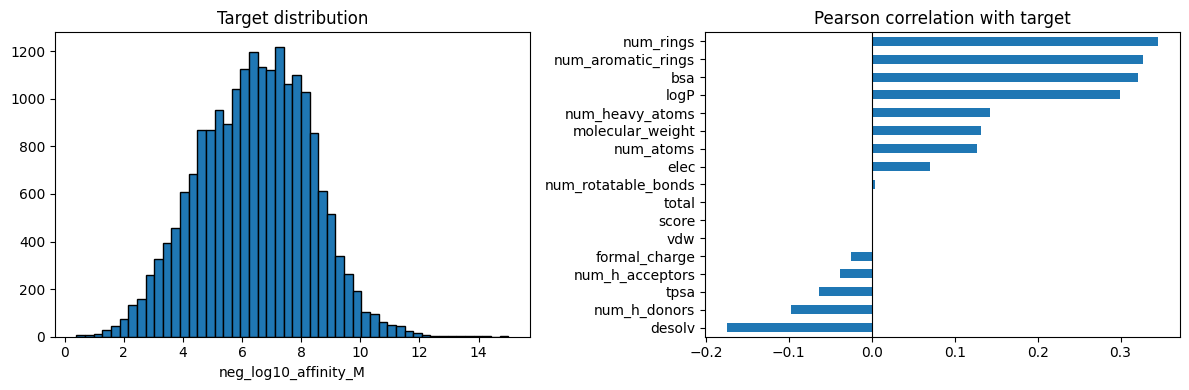

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y, bins=50, edgecolor="k")
axes[0].set_xlabel(TARGET_COL)
axes[0].set_title("Target distribution")

corr = X.corrwith(pd.Series(y, name=TARGET_COL)).sort_values()
corr.plot(kind="barh", ax=axes[1])
axes[1].set_title("Pearson correlation with target")
axes[1].axvline(0, color="k", linewidth=0.8)

plt.tight_layout()
plt.show()

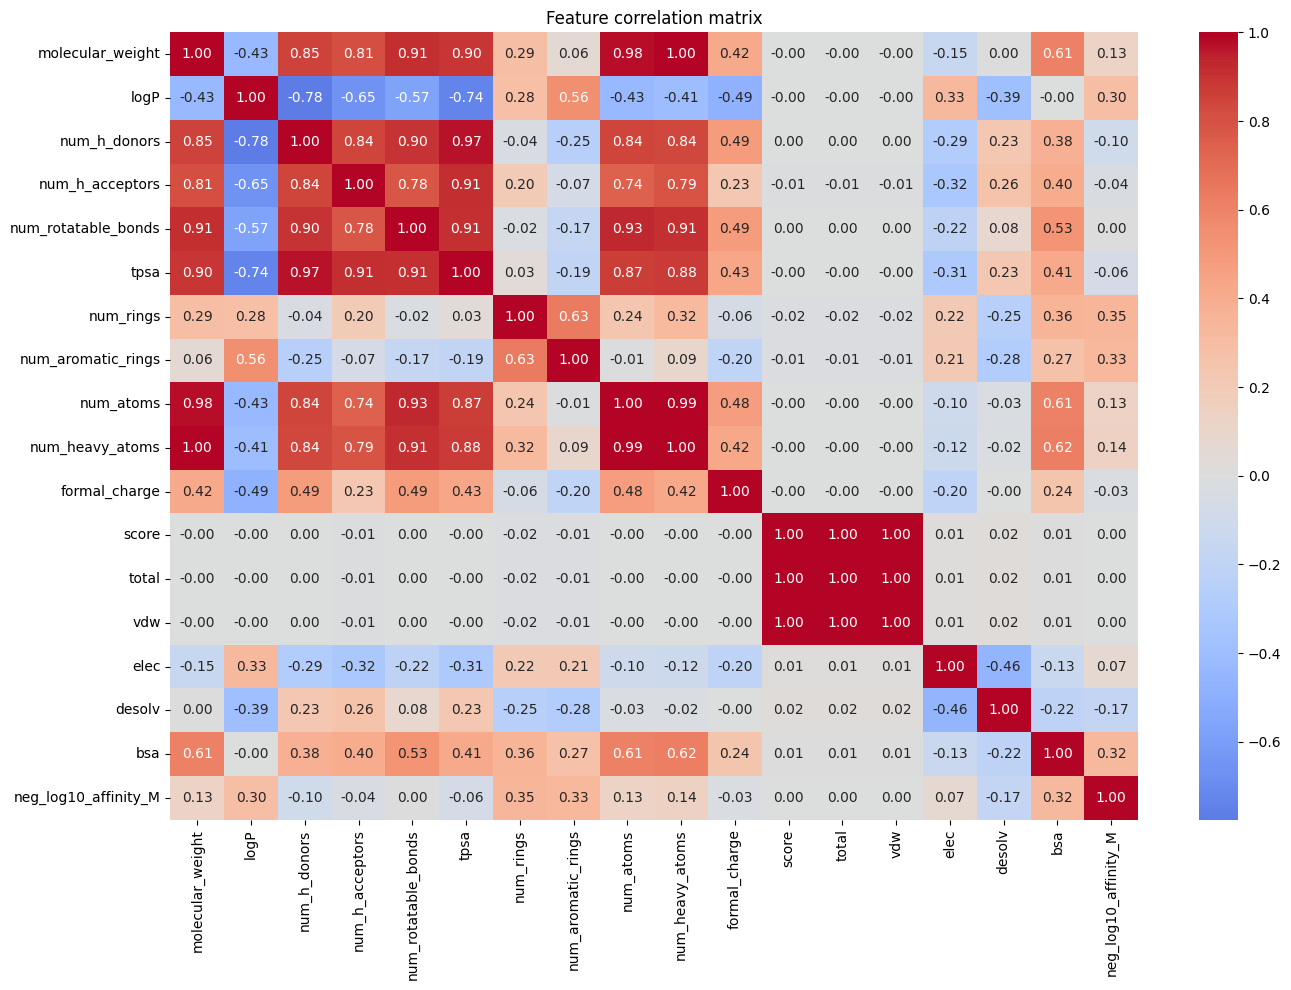

In [5]:
# Correlation heatmap (features + target)
corr_matrix = pd.concat([X, pd.Series(y, name=TARGET_COL)], axis=1).corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

## 4. Train / Test Split

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)
print(f"Train: {len(X_train)}  |  Test: {len(X_test)}")

Train: 15998  |  Test: 4000


## 5. Model Training
Three complementary models: Random Forest, XGBoost, and a regularised linear baseline (Ridge).

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import xgboost as xgb

models = {
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  Ridge(alpha=1.0))
    ]),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, max_features="sqrt",
        n_jobs=-1, random_state=RANDOM_SEED
    ),
    "XGBoost": xgb.XGBRegressor(
        n_estimators=500, learning_rate=0.05,
        max_depth=6, subsample=0.8,
        colsample_bytree=0.8, n_jobs=-1,
        random_state=RANDOM_SEED, verbosity=0
    )
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    results[name] = {
        "R2":   r2_score(y_test, preds),
        "MAE":  mean_absolute_error(y_test, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "preds": preds
    }
    print(f"{name:>15}  R²={results[name]['R2']:.3f}  MAE={results[name]['MAE']:.3f}  RMSE={results[name]['RMSE']:.3f}")

          Ridge  R²=0.256  MAE=1.293  RMSE=1.624
  Random Forest  R²=0.474  MAE=1.073  RMSE=1.366
        XGBoost  R²=0.444  MAE=1.110  RMSE=1.405


## 6. Cross-validated Performance

In [8]:
from sklearn.model_selection import cross_val_score

print("5-fold CV R² (full dataset):")
for name, model in models.items():
    cv_scores = cross_val_score(model, X, y, cv=5, scoring="r2", n_jobs=-1)
    print(f"  {name:>15}: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

5-fold CV R² (full dataset):
            Ridge: 0.220 ± 0.013
    Random Forest: 0.430 ± 0.019
          XGBoost: 0.400 ± 0.021


## 7. Predicted vs Actual Plots

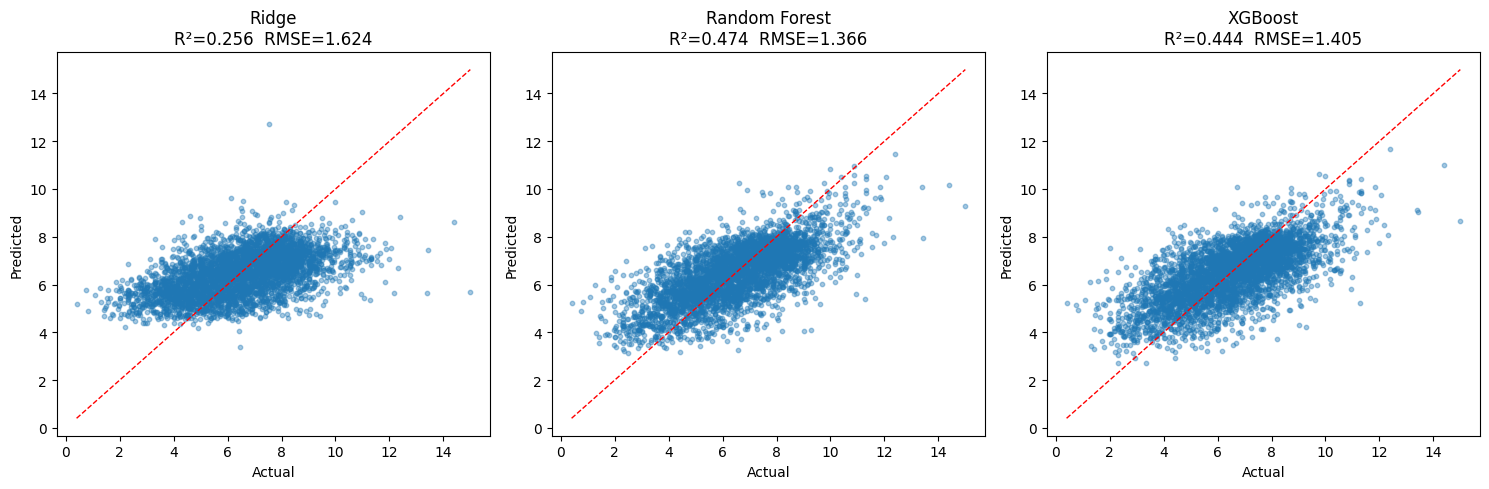

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, res) in zip(axes, results.items()):
    ax.scatter(y_test, res["preds"], alpha=0.4, s=10)
    lims = [min(y_test.min(), res["preds"].min()),
            max(y_test.max(), res["preds"].max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{name}\nR²={res['R2']:.3f}  RMSE={res['RMSE']:.3f}")
plt.tight_layout()
plt.show()

## 8. Feature Importance

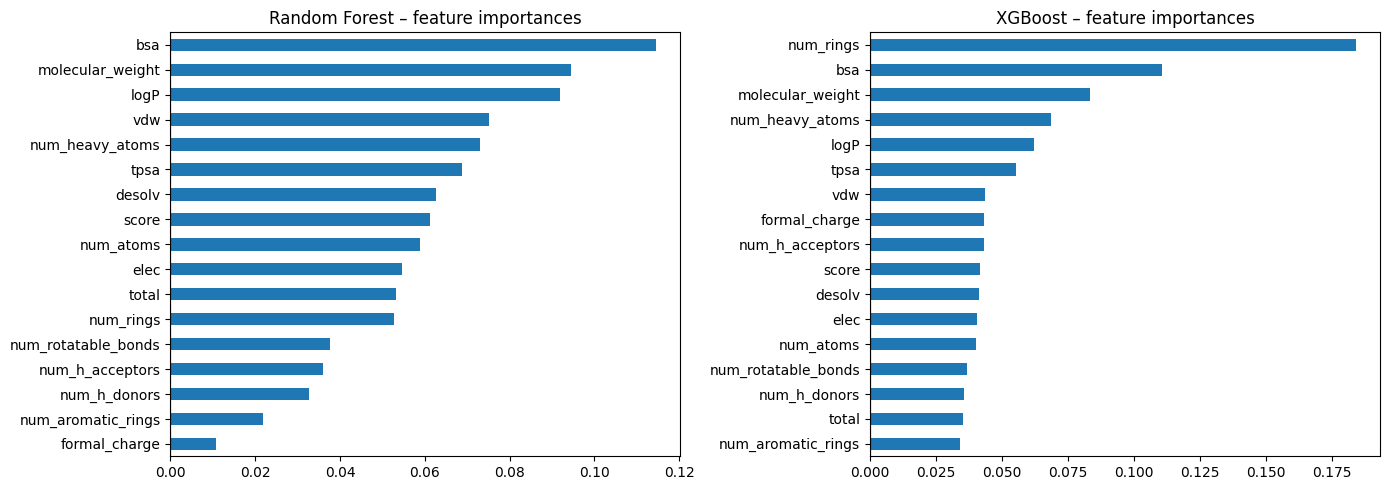

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, key in zip(axes, ["Random Forest", "XGBoost"]):
    importances = pd.Series(
        models[key].feature_importances_, index=FEATURES
    ).sort_values(ascending=True)
    importances.plot(kind="barh", ax=ax)
    ax.set_title(f"{key} – feature importances")
    ax.axvline(0, color="k", linewidth=0.8)

plt.tight_layout()
plt.show()

## 9. SHAP Explainability (XGBoost)

/Users/sguirale/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


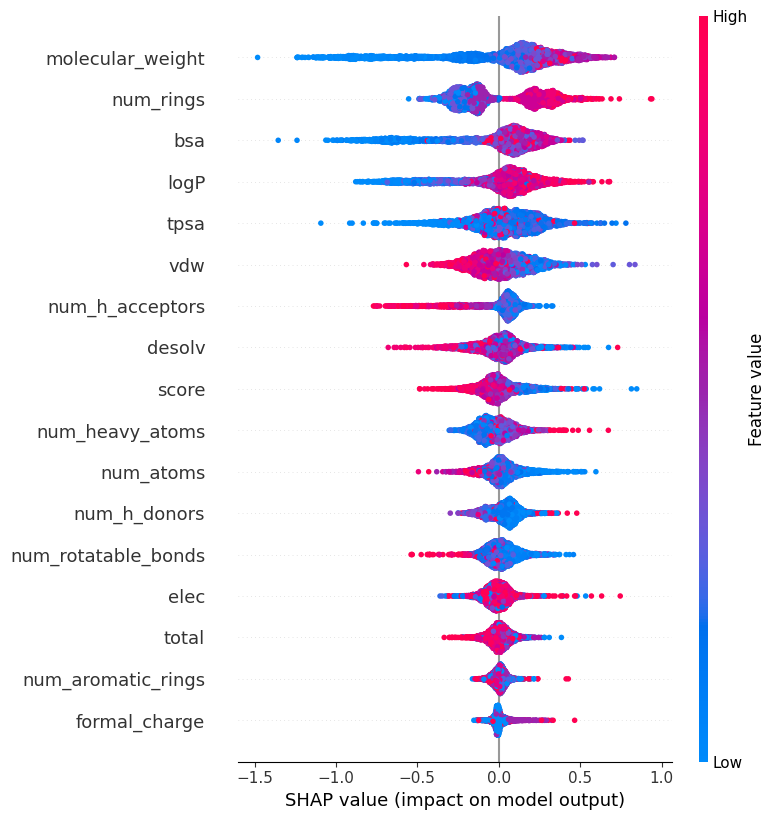

In [11]:
import shap

explainer   = shap.TreeExplainer(models["XGBoost"])
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=True)

## 10. Hyperparameter Tuning (XGBoost – optional)

In [12]:
# Uncomment to run (can be slow on large datasets)

from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators":     [300, 500, 800],
    "max_depth":        [4, 6, 8],
    "learning_rate":    [0.01, 0.05, 0.1],
    "subsample":        [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}

search = RandomizedSearchCV(
    xgb.XGBRegressor(n_jobs=-1, random_state=RANDOM_SEED, verbosity=0),
    param_dist, n_iter=30, cv=5, scoring="r2",
    random_state=RANDOM_SEED, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print("Best CV R²:", search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV R²: 0.4247738736368697


## 11. Save the Best Model

In [13]:
import joblib

best_model_name = max(results, key=lambda k: results[k]["R2"])
print(f"Best model: {best_model_name}  (R²={results[best_model_name]['R2']:.3f})")

joblib.dump(models[best_model_name], "20k_best_binding_affinity_model.pkl")
print("Saved → 20k_best_binding_affinity_model.pkl")

Best model: Random Forest  (R²=0.474)
Saved → 20k_best_binding_affinity_model.pkl


## 12. Predict on New Compounds

In [ ]:
# Load model and predict on a new CSV
# new_df = pd.read_csv("new_compounds.csv", sep=None, engine="python")
# X_new  = pd.DataFrame(imputer.transform(new_df[FEATURES]), columns=FEATURES)
# best   = joblib.load("best_binding_affinity_model.pkl")
# new_df["predicted_" + TARGET_COL] = best.predict(X_new)
# new_df.to_csv("predictions.csv", index=False)
# new_df.head()